In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:

import pandas as pd
from pathlib import Path
from tkinter import Tk, filedialog

feature_names = [
    'x-box', 'y-box', 'width', 'high',
    'onpix', 'x-bar', 'y-bar', 'x2bar',
    'y2bar', 'xybar', 'x2ybr', 'xy2br',
    'x-ege', 'xegvy', 'y-ege', 'yegvx'
]

# Open file selection window
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_path = filedialog.askopenfilename(
    title="Select letter-recognition(2).data",
    filetypes=[("Data files", "*.data"), ("All files", "*.*")]
)

root.destroy()

if not file_path:
    raise FileNotFoundError(
        "No dataset selected. Please select letter-recognition(2).data."
    )

# Load the dataset
df = pd.read_csv(
    file_path,
    header=None,
    names=['letter'] + feature_names
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Dataset location:", file_path)

display(df.head())


Dataset loaded successfully!
Dataset shape: (20000, 17)
Dataset location: C:/Users/fhana/Downloads/letter+recognition/letter-recognition.data


,letter,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


In [10]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   letter  20000 non-null  object
 1   x-box   20000 non-null  int64 
 2   y-box   20000 non-null  int64 
 3   width   20000 non-null  int64 
 4   high    20000 non-null  int64 
 5   onpix   20000 non-null  int64 
 6   x-bar   20000 non-null  int64 
 7   y-bar   20000 non-null  int64 
 8   x2bar   20000 non-null  int64 
 9   y2bar   20000 non-null  int64 
 10  xybar   20000 non-null  int64 
 11  x2ybr   20000 non-null  int64 
 12  xy2br   20000 non-null  int64 
 13  x-ege   20000 non-null  int64 
 14  xegvy   20000 non-null  int64 
 15  y-ege   20000 non-null  int64 
 16  yegvx   20000 non-null  int64 
dtypes: int64(16), object(1)
memory usage: 2.6+ MB

Missing values:
letter    0
x-box     0
y-box     0
width     0
high      0
onpix     0
x-bar     0
y-bar     0
x2bar     0
y2bar     

,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
count,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000
mean,4.023550,7.035500,5.121850,5.37245,3.505850,6.897600,7.500450,4.628600,5.178650,8.282050,6.45400,7.929000,3.046100,8.338850,3.691750,7.80120
std,1.913212,3.304555,2.014573,2.26139,2.190458,2.026035,2.325354,2.699968,2.380823,2.488475,2.63107,2.080619,2.332541,1.546722,2.567073,1.61747
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,3.000000,5.000000,4.000000,4.00000,2.000000,6.000000,6.000000,3.000000,4.000000,7.000000,5.00000,7.000000,1.000000,8.000000,2.000000,7.00000
50%,4.000000,7.000000,5.000000,6.00000,3.000000,7.000000,7.000000,4.000000,5.000000,8.000000,6.00000,8.000000,3.000000,8.000000,3.000000,8.00000
75%,5.000000,9.000000,6.000000,7.00000,5.000000,8.000000,9.000000,6.000000,7.000000,10.000000,8.00000,9.000000,4.000000,9.000000,5.000000,9.00000
max,15.000000,15.000000,15.000000,15.00000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.00000,15.000000,15.000000,15.000000,15.000000,15.00000


Class distribution:
letter
0    19211
1      789
Name: count, dtype: int64
Minority class: 789
Majority class: 19211
Imbalance ratio: 24.35


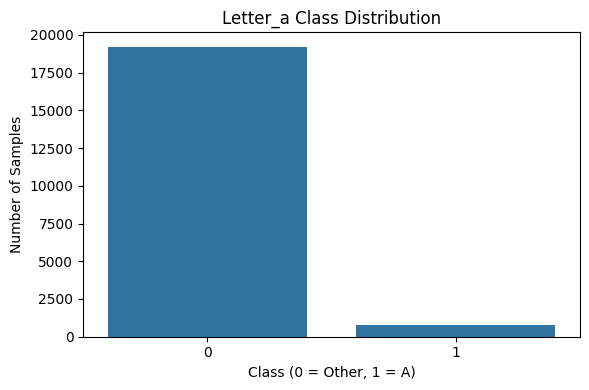

In [11]:
X = df[feature_names].copy()

y = (df['letter'] == 'A').astype(int)

print("Class distribution:")
print(y.value_counts().sort_index())

minority = (y == 1).sum()
majority = (y == 0).sum()

print("Minority class:", minority)
print("Majority class:", majority)
print("Imbalance ratio:", round(majority / minority, 2))

plt.figure(figsize=(6, 4))
sns.countplot(x=y)

plt.title("Letter_a Class Distribution")
plt.xlabel("Class (0 = Other, 1 = A)")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 16000
Testing samples: 4000

Training class distribution:
letter
0    15369
1      631
Name: count, dtype: int64

Testing class distribution:
letter
0    3842
1     158
Name: count, dtype: int64


In [13]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", RobustScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "LDA": Pipeline([
        ("scaler", RobustScaler()),
        ("classifier", LinearDiscriminantAnalysis())
    ])
}

print("Baseline models created successfully!")

Baseline models created successfully!


In [14]:
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(f"{name} training completed!\n")

Training Logistic Regression...
Logistic Regression training completed!

Training LDA...
LDA training completed!



In [15]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "AUROC": roc_auc_score(y_test, y_prob),
        "AUPRC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,AUROC,AUPRC
0,Logistic Regression,0.9895,0.8867,0.8418,0.8636,0.9911,0.9302
1,LDA,0.9885,0.8373,0.8797,0.8580,0.9861,0.9078


In [16]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Other Letters", "Letter A"],
        zero_division=0
    ))

Logistic Regression
               precision    recall  f1-score   support

Other Letters       0.99      1.00      0.99      3842
     Letter A       0.89      0.84      0.86       158

     accuracy                           0.99      4000
    macro avg       0.94      0.92      0.93      4000
 weighted avg       0.99      0.99      0.99      4000

LDA
               precision    recall  f1-score   support

Other Letters       1.00      0.99      0.99      3842
     Letter A       0.84      0.88      0.86       158

     accuracy                           0.99      4000
    macro avg       0.92      0.94      0.93      4000
 weighted avg       0.99      0.99      0.99      4000



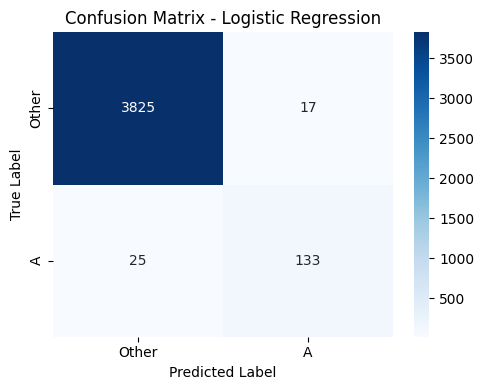

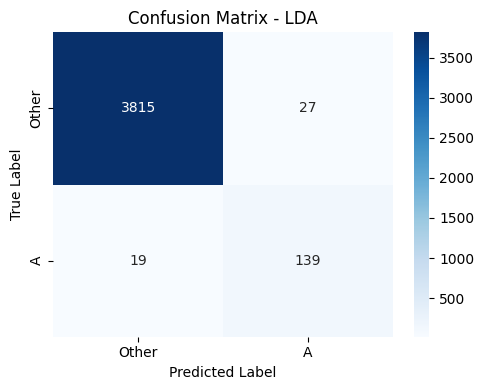

In [17]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Other", "A"],
        yticklabels=["Other", "A"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.tight_layout()
    plt.show()

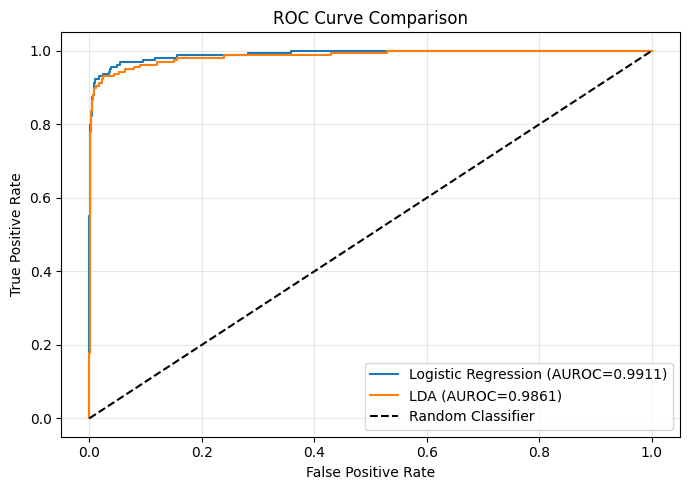

In [18]:
plt.figure(figsize=(7, 5))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUROC={auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

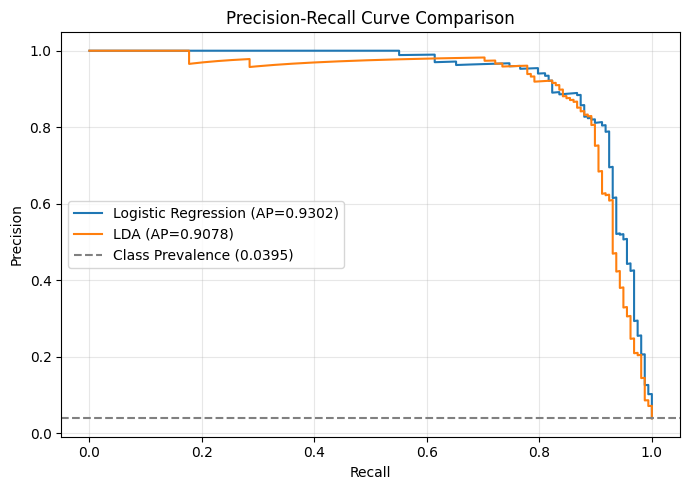

In [19]:
plt.figure(figsize=(7, 5))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test, y_prob
    )

    ap_score = average_precision_score(
        y_test, y_prob
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap_score:.4f})"
    )

baseline_rate = y_test.mean()

plt.axhline(
    baseline_rate,
    linestyle="--",
    color="gray",
    label=f"Class Prevalence ({baseline_rate:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, model in models.items():

    print(f"Cross-validating {name}...")

    cv_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    cv_results.append({
        "Model": name,
        "CV AUROC": roc_auc_score(y_train, cv_prob),
        "CV AUPRC": average_precision_score(
            y_train, cv_prob
        )
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

Cross-validating Logistic Regression...
Cross-validating LDA...


,Model,CV AUROC,CV AUPRC
0,Logistic Regression,0.9853,0.9074
1,LDA,0.9740,0.8880


In [21]:
paper_results = pd.DataFrame({
    "Method": [
        "Authors - LDA (No Sampling)",
        "Authors - LDA (Random Oversampling)",
        "Authors - LDA (SMOTE)",
        "Authors - LDA (Random Undersampling)",
        "Authors - LDA (SMOTETomek)"
    ],
    "AUPRC": [
        0.8917,
        0.8457,
        0.8412,
        0.8506,
        0.8412
    ],
    "AUROC": [
        0.9765,
        0.9851,
        0.9848,
        0.9851,
        0.9848
    ]
})

our_results = results_df[
    ["Model", "AUPRC", "AUROC"]
].copy()

our_results["Method"] = (
    "Our - " + our_results["Model"] + " (No Sampling)"
)

our_results = our_results[
    ["Method", "AUPRC", "AUROC"]
]

comparison_df = pd.concat(
    [our_results, paper_results],
    ignore_index=True
)

display(comparison_df.round(4))

,Method,AUPRC,AUROC
0,Our - Logistic Regression (No Sampling),0.9302,0.9911
1,Our - LDA (No Sampling),0.9078,0.9861
2,Authors - LDA (No Sampling),0.8917,0.9765
3,Authors - LDA (Random Oversampling),0.8457,0.9851
4,Authors - LDA (SMOTE),0.8412,0.9848
5,Authors - LDA (Random Undersampling),0.8506,0.9851
6,Authors - LDA (SMOTETomek),0.8412,0.9848


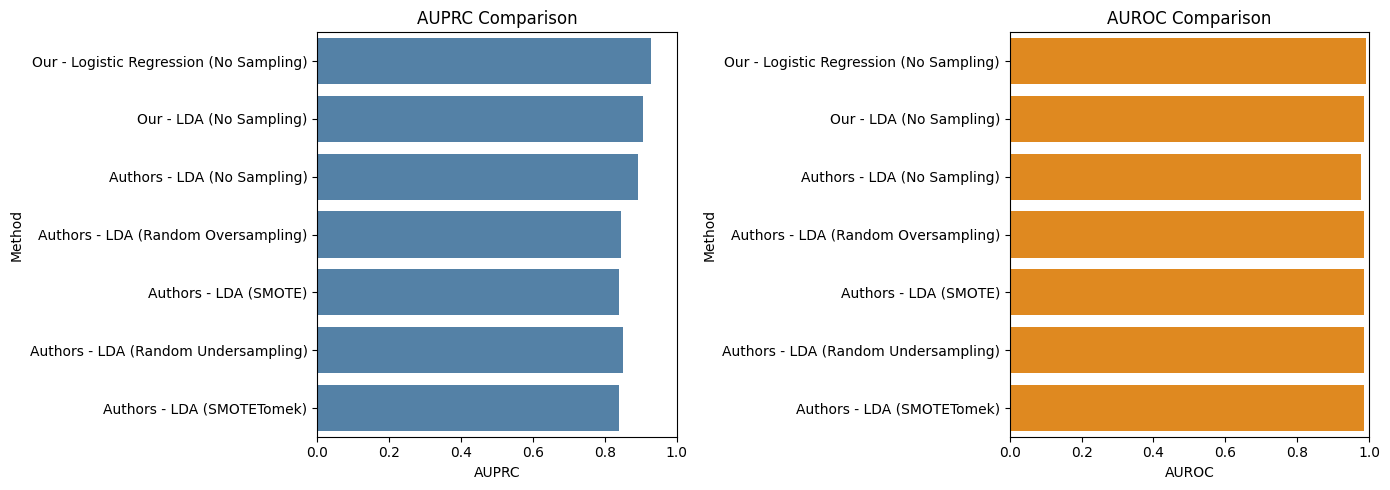

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=comparison_df,
    x="AUPRC",
    y="Method",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("AUPRC Comparison")
axes[0].set_xlim(0, 1)

sns.barplot(
    data=comparison_df,
    x="AUROC",
    y="Method",
    ax=axes[1],
    color="darkorange"
)

axes[1].set_title("AUROC Comparison")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

In [23]:
results_df.to_csv(
    "phase2_baseline_results.csv",
    index=False
)

cv_results_df.to_csv(
    "phase2_cross_validation_results.csv",
    index=False
)

comparison_df.to_csv(
    "phase2_paper_comparison.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
